In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

wilayah_miskin = pd.read_excel('data/Dataset_Final.xlsx', sheet_name='Dataset_114')
var = ["PPM", "TPAK", "TPT", "PDRB", "KP"]
X_prediktor = wilayah_miskin[var]
Y_target = wilayah_miskin["IPM"]
grup = wilayah_miskin["Kabupaten/Kota"]
print(wilayah_miskin.shape, grup.nunique(), "daerah")

def hitung_metrik(y_asli, y_pred):
    return {"MAE": mean_absolute_error(y_asli, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_asli, y_pred))),
            "R2": r2_score(y_asli, y_pred)}

(1026, 9) 114 daerah


Pembagian data latih dan uji berdasarkan kabupaten.

In [6]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_latih, idx_uji = next(split.split(X_prediktor, Y_target, groups=grup))
data_latih, data_uji = wilayah_miskin.iloc[idx_latih], wilayah_miskin.iloc[idx_uji]
X_latih, y_latih = X_prediktor.iloc[idx_latih], Y_target.iloc[idx_latih]
X_uji, y_uji = X_prediktor.iloc[idx_uji], Y_target.iloc[idx_uji]
print("latih:", data_latih.shape, data_latih["Kabupaten/Kota"].nunique(), "daerah")
print("uji  :", data_uji.shape, data_uji["Kabupaten/Kota"].nunique(), "daerah")

latih: (819, 9) 91 daerah
uji  : (207, 9) 23 daerah


tuning hyperparameter untuk data latih

In [7]:
grid = {"n_estimators": [100, 200, 300, 400, 500, 600, 700, 800, 1000],
        "max_depth": [2, 3, 4, 6, 8, 10],
        "learning_rate": [0.01,0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1],
        "min_child_weight": [1, 5]}
model_dasar = XGBRegressor(objective="reg:squarederror", tree_method="exact", reg_lambda=1, reg_alpha=0, gamma=0,
                           base_score=float(y_latih.mean()), random_state=0)
pencarian = GridSearchCV(model_dasar, grid, cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error", n_jobs=-1)
pencarian.fit(X_latih, y_latih, groups=data_latih["Kabupaten/Kota"])
param_terbaik = pencarian.best_params_
print("Parameter terbaik :", param_terbaik)
print("MAE validasi      :", round(-pencarian.best_score_, 3))

hasil_tuning = pd.DataFrame(pencarian.cv_results_)
hasil_tuning["MAE_validasi"] = -hasil_tuning["mean_test_score"]
hasil_tuning["SD"] = hasil_tuning["std_test_score"]
hasil_tuning.sort_values("rank_test_score")[["params", "MAE_validasi", "SD"]].head(10).round(3)

Parameter terbaik : {'learning_rate': 0.04, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 100}
MAE validasi      : 3.414


,params,MAE_validasi,SD
333,"{'learning_rate': 0.04, 'max_depth': 2, 'min_c...",3.414,0.543
324,"{'learning_rate': 0.04, 'max_depth': 2, 'min_c...",3.414,0.544
12,"{'learning_rate': 0.01, 'max_depth': 2, 'min_c...",3.428,0.543
118,"{'learning_rate': 0.02, 'max_depth': 2, 'min_c...",3.431,0.547
216,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c...",3.432,0.568
3,"{'learning_rate': 0.01, 'max_depth': 2, 'min_c...",3.432,0.542
109,"{'learning_rate': 0.02, 'max_depth': 2, 'min_c...",3.432,0.548
225,"{'learning_rate': 0.03, 'max_depth': 2, 'min_c...",3.433,0.569
11,"{'learning_rate': 0.01, 'max_depth': 2, 'min_c...",3.437,0.572
2,"{'learning_rate': 0.01, 'max_depth': 2, 'min_c...",3.437,0.572


Evaluasi model final di data uji (23 daerah), dibandingkan dengan baseline dan parameter awal.

In [8]:
model_final = pencarian.best_estimator_          # sudah dilatih ulang di seluruh data latih
pred_uji = model_final.predict(X_uji)
pred_latih = model_final.predict(X_latih)
pred_baseline = np.full(len(y_uji), y_latih.mean())

m_awal = XGBRegressor(objective="reg:squarederror", tree_method="exact", n_estimators=1000, max_depth=2, learning_rate=0.01,
                      reg_lambda=1, reg_alpha=0, gamma=0, base_score=float(y_latih.mean()), random_state=0).fit(X_latih, y_latih)

evaluasi = pd.DataFrame({"Baseline (rata-rata latih)": hitung_metrik(y_uji, pred_baseline),
                         "XGBoost tuning - data latih": hitung_metrik(y_latih, pred_latih),
                         "XGBoost tuning - data uji": hitung_metrik(y_uji, pred_uji),
                         "XGBoost parameter awal - data uji": hitung_metrik(y_uji, m_awal.predict(X_uji))}).T.round(3)
evaluasi

,MAE,RMSE,R2
Baseline (rata-rata latih),6.500,8.390,-0.019
XGBoost tuning - data latih,2.363,3.035,0.819
XGBoost tuning - data uji,2.611,3.388,0.834
XGBoost parameter awal - data uji,2.782,3.712,0.801


Group kfold validation (5 fold) pake 114 daerah (semuanya masuk)

In [9]:
param_terbaik = pencarian.best_params_          # hasil tuning langkah B
grup = wilayah_miskin["Kabupaten/Kota"]
kfold = GroupKFold(n_splits=5)

ipm_prediksi = np.zeros(len(wilayah_miskin))      # diisi bertahap per fold
nomor_fold = np.zeros(len(wilayah_miskin), dtype=int)
hasil_fold = []

for i, (idx_latih_f, idx_val_f) in enumerate(kfold.split(X_prediktor, Y_target, groups=grup), start=1):
    model_fold = XGBRegressor(objective="reg:squarederror", tree_method="exact",
                              reg_lambda=1, reg_alpha=0, gamma=0,
                              base_score=float(Y_target.iloc[idx_latih_f].mean()),
                              random_state=0, **param_terbaik)
    model_fold.fit(X_prediktor.iloc[idx_latih_f], Y_target.iloc[idx_latih_f])

    pred = model_fold.predict(X_prediktor.iloc[idx_val_f])
    ipm_prediksi[idx_val_f] = pred
    nomor_fold[idx_val_f] = i
    hasil_fold.append({"Fold": i,
                       "Daerah validasi": grup.iloc[idx_val_f].nunique(),
                       "Baris": len(idx_val_f),
                       **hitung_metrik(Y_target.iloc[idx_val_f], pred)})

tabel_fold = pd.DataFrame(hasil_fold)
print(tabel_fold.round(3))
print(tabel_fold[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(3))

metrik_silang = hitung_metrik(Y_target, ipm_prediksi)
print("Prediksi silang 1.026 baris:", {k: round(float(v), 3) for k, v in metrik_silang.items()})

   Fold  Daerah validasi  Baris    MAE   RMSE     R2
0     1               23    207  2.541  3.397  0.686
1     2               23    207  3.239  4.345  0.690
2     3               23    207  3.392  4.804  0.710
3     4               23    207  3.387  4.038  0.619
4     5               22    198  2.981  4.059  0.596
        MAE   RMSE    R2
mean  3.108  4.129  0.66
std   0.358  0.513  0.05
Prediksi silang 1.026 baris: {'MAE': 3.109, 'RMSE': 4.155, 'R2': 0.684}


Tabel IPM prediksi dan status

In [10]:
ambang = metrik_silang["MAE"]

tabel_prediksi = wilayah_miskin[["Kabupaten/Kota", "Provinsi", "Tahun", "IPM"]].copy()
tabel_prediksi["IPM_prediksi"] = ipm_prediksi.round(2)
tabel_prediksi["Selisih"] = (tabel_prediksi["IPM"] - tabel_prediksi["IPM_prediksi"]).round(2)
tabel_prediksi["Status"] = np.select(
    [tabel_prediksi["Selisih"] > ambang, tabel_prediksi["Selisih"] < -ambang],
    ["Di atas prediksi", "Di bawah prediksi"],
    default="Sesuai prediksi")
tabel_prediksi["Fold"] = nomor_fold

print("Ambang status: ±", round(ambang, 2))
print(tabel_prediksi["Status"].value_counts())
tabel_prediksi.head()

Ambang status: ± 3.11
Status
Sesuai prediksi      637
Di atas prediksi     209
Di bawah prediksi    180
Name: count, dtype: int64


,Kabupaten/Kota,Provinsi,Tahun,IPM,IPM_prediksi,Selisih,Status,Fold
0,Aceh Barat,Aceh,2017,70.20,69.12,1.08,Sesuai prediksi,4
1,Aceh Barat,Aceh,2018,70.47,69.12,1.35,Sesuai prediksi,4
2,Aceh Barat,Aceh,2019,71.22,69.18,2.04,Sesuai prediksi,4
3,Aceh Barat,Aceh,2020,71.38,69.18,2.20,Sesuai prediksi,4
4,Aceh Barat,Aceh,2021,71.67,69.18,2.49,Sesuai prediksi,4


In [11]:
# ===== C3. Model tanpa tuning (pembanding) =====
param_awal = {"n_estimators": 1000, "max_depth": 2, "learning_rate": 0.01, "min_child_weight": 1}

# (a) Dilatih di data latih, dievaluasi di data uji (80/20)
model_awal = XGBRegressor(objective="reg:squarederror", tree_method="exact",
                          reg_lambda=1, reg_alpha=0, gamma=0,
                          base_score=float(y_latih.mean()),
                          random_state=0, **param_awal)
model_awal.fit(X_latih, y_latih)
metrik_uji_awal = hitung_metrik(y_uji, model_awal.predict(X_uji))
metrik_uji_tuning = hitung_metrik(y_uji, pencarian.best_estimator_.predict(X_uji))

# (b) Prediksi silang GroupKFold 5 di 114 daerah (fold sama dengan C1)
ipm_prediksi_awal = np.zeros(len(wilayah_miskin))
hasil_fold_awal = []
for i, (idx_latih_f, idx_val_f) in enumerate(kfold.split(X_prediktor, Y_target, groups=grup), start=1):
    model_fold = XGBRegressor(objective="reg:squarederror", tree_method="exact",
                              reg_lambda=1, reg_alpha=0, gamma=0,
                              base_score=float(Y_target.iloc[idx_latih_f].mean()),
                              random_state=0, **param_awal)
    model_fold.fit(X_prediktor.iloc[idx_latih_f], Y_target.iloc[idx_latih_f])
    pred = model_fold.predict(X_prediktor.iloc[idx_val_f])
    ipm_prediksi_awal[idx_val_f] = pred
    hasil_fold_awal.append({"Fold": i,
                            "Daerah validasi": grup.iloc[idx_val_f].nunique(),
                            "Baris": len(idx_val_f),
                            **hitung_metrik(Y_target.iloc[idx_val_f], pred)})

tabel_fold_awal = pd.DataFrame(hasil_fold_awal)
metrik_silang_awal = hitung_metrik(Y_target, ipm_prediksi_awal)

# (c) Perbandingan kedua model
perbandingan = pd.DataFrame({
    "Tanpa tuning": {**{f"Uji {k}": v for k, v in metrik_uji_awal.items()},
                     "MAE fold rata-rata": tabel_fold_awal["MAE"].mean(),
                     "MAE fold SD": tabel_fold_awal["MAE"].std(),
                     **{f"Silang {k}": v for k, v in metrik_silang_awal.items()}},
    "Dengan tuning": {**{f"Uji {k}": v for k, v in metrik_uji_tuning.items()},
                      "MAE fold rata-rata": tabel_fold["MAE"].mean(),
                      "MAE fold SD": tabel_fold["MAE"].std(),
                      **{f"Silang {k}": v for k, v in metrik_silang.items()}},
})
perbandingan.round(3)

,Tanpa tuning,Dengan tuning
Uji MAE,2.782,2.611
Uji RMSE,3.712,3.388
Uji R2,0.801,0.834
MAE fold rata-rata,3.061,3.108
MAE fold SD,0.319,0.358
Silang MAE,3.062,3.109
Silang RMSE,4.034,4.155
Silang R2,0.703,0.684


D. MAE per provinsi, per tahun, dan kontribusi fitur

In [12]:
per_prov = tabel_prediksi.assign(galat=lambda d: d["Selisih"].abs()).groupby("Provinsi").agg(
    Daerah=("Kabupaten/Kota", "nunique"), MAE=("galat", "mean"), Rata_selisih=("Selisih", "mean")).round(2)
print(per_prov.sort_values("MAE", ascending=False).to_string())
print()
print(tabel_prediksi.groupby("Tahun")["Selisih"].agg(["mean", lambda s: s.abs().mean()]).rename(columns={"mean": "Rata_selisih", "<lambda_0>": "MAE"}).round(2))

                     Daerah   MAE  Rata_selisih
Provinsi                                       
Papua                    24  5.06         -2.06
D I Yogyakarta            2  4.94          4.94
Sulawesi Barat            1  3.90         -3.90
Bengkulu                  5  3.84          3.63
Aceh                     12  3.24          2.26
Papua Barat              12  3.07          1.31
Sulawesi Tengah           4  2.80         -0.51
Jawa Timur                4  2.53         -2.30
Sulawesi Tenggara         1  2.35         -2.21
Gorontalo                 4  2.32         -0.79
Sumatera Utara            5  2.26         -1.32
Nusa Tenggara Timur      17  2.26         -0.16
Maluku                   10  2.10          0.95
Nusa Tenggara Barat       2  1.79          1.65
Sumatera Selatan          3  1.71         -1.36
Jawa Tengah               5  1.67          0.76
Riau                      1  1.41         -1.36
Maluku Utara              1  1.32         -0.27
Lampung                   1  0.98       

In [13]:
gain = pd.Series(model_final.get_booster().get_score(importance_type="total_gain")).reindex(var).fillna(0)
kontribusi = (gain / gain.sum() * 100).sort_values()
kontribusi.round(1).sort_values(ascending=False)  

PPM     44.6
TPAK    22.2
KP      14.2
TPT     11.3
PDRB     7.6
dtype: float64

In [15]:
# ===== Langkah E: ekspor artefak ke folder aplikasi =====
import json
from pathlib import Path
import joblib
import xgboost

# --- Folder tujuan (relatif dari folder notebook/) ---
FOLDER_APP = Path("../main_app")
FOLDER_MODEL = FOLDER_APP / "model"
FOLDER_DATA = FOLDER_APP / "data"
FOLDER_MODEL.mkdir(parents=True, exist_ok=True)
FOLDER_DATA.mkdir(parents=True, exist_ok=True)

kolom_prediktor = list(X_prediktor.columns)

# --- E1. Model final: 2 model x 2 format ---
for nama, param in {"tuning": param_terbaik, "awal": param_awal}.items():
    model_final = XGBRegressor(objective="reg:squarederror", tree_method="exact",
                               reg_lambda=1, reg_alpha=0, gamma=0,
                               base_score=float(Y_target.mean()),
                               random_state=0, **param)
    model_final.fit(X_prediktor, Y_target)                               # seluruh 1.026 baris
    model_final.save_model(FOLDER_MODEL / f"model_{nama}.json")          # format 1
    joblib.dump(model_final, FOLDER_MODEL / f"model_{nama}.joblib")      # format 2
    if nama == "tuning":
        gain = model_final.get_booster().get_score(importance_type="total_gain")

# --- E2. Tabel untuk aplikasi ---
tabel_app = tabel_prediksi.join(X_prediktor)
tabel_app["IPM_prediksi_tanpa_tuning"] = ipm_prediksi_awal.round(2)
tabel_app.to_csv(FOLDER_DATA / "tabel_prediksi.csv", index=False)

# --- E3. Info model ---
def rapikan(d):
    return {k: round(float(v), 4) for k, v in d.items()}

total_gain = sum(gain.values())
info = {
    "versi_xgboost": xgboost.__version__,
    "kolom_prediktor": kolom_prediktor,
    "jumlah": {"daerah": int(grup.nunique()), "baris": len(wilayah_miskin),
               "tahun_awal": int(wilayah_miskin["Tahun"].min()),
               "tahun_akhir": int(wilayah_miskin["Tahun"].max())},
    "param": {"tuning": param_terbaik, "awal": param_awal},
    "ambang_status": round(float(metrik_silang["MAE"]), 2),
    "metrik_uji": {
        "Baseline": rapikan(hitung_metrik(y_uji, np.full(len(y_uji), y_latih.mean()))),
        "Tanpa tuning": rapikan(hitung_metrik(y_uji, model_awal.predict(X_uji))),
        "Dengan tuning": rapikan(hitung_metrik(y_uji, pencarian.best_estimator_.predict(X_uji))),
    },
    "metrik_prediksi_silang": {"tuning": rapikan(metrik_silang), "awal": rapikan(metrik_silang_awal)},
    "tabel_fold": {"tuning": tabel_fold.round(4).to_dict("records"),
                   "awal": tabel_fold_awal.round(4).to_dict("records")},
    "rentang_prediktor": {k: {"min": float(X_prediktor[k].min()), "max": float(X_prediktor[k].max())}
                          for k in kolom_prediktor},
    "kontribusi_fitur": {k: round(v / total_gain * 100, 2) for k, v in gain.items()},
}
with open(FOLDER_MODEL / "info_model.json", "w", encoding="utf-8") as f:
    json.dump(info, f, indent=2, default=float)

# --- E4. Cek ---
cek_json = XGBRegressor()
cek_json.load_model(FOLDER_MODEL / "model_tuning.json")
cek_joblib = joblib.load(FOLDER_MODEL / "model_tuning.joblib")
print("Prediksi json = joblib:", np.allclose(cek_json.predict(X_prediktor), cek_joblib.predict(X_prediktor)))
print("Isi folder model:", sorted(p.name for p in FOLDER_MODEL.iterdir()))
print("Isi folder data :", sorted(p.name for p in FOLDER_DATA.iterdir()))
print(json.dumps(info["metrik_uji"], indent=2))

Prediksi json = joblib: True
Isi folder model: ['info_model.json', 'model_awal.joblib', 'model_awal.json', 'model_tuning.joblib', 'model_tuning.json']
Isi folder data : ['tabel_prediksi.csv']
{
  "Baseline": {
    "MAE": 6.4998,
    "RMSE": 8.3902,
    "R2": -0.0186
  },
  "Tanpa tuning": {
    "MAE": 2.7818,
    "RMSE": 3.7116,
    "R2": 0.8007
  },
  "Dengan tuning": {
    "MAE": 2.6109,
    "RMSE": 3.3879,
    "R2": 0.8339
  }
}


In [16]:
import sys
print(sys.executable)

c:\Users\samuel\AppData\Local\Programs\Python\Python312\python.exe


## Grafik

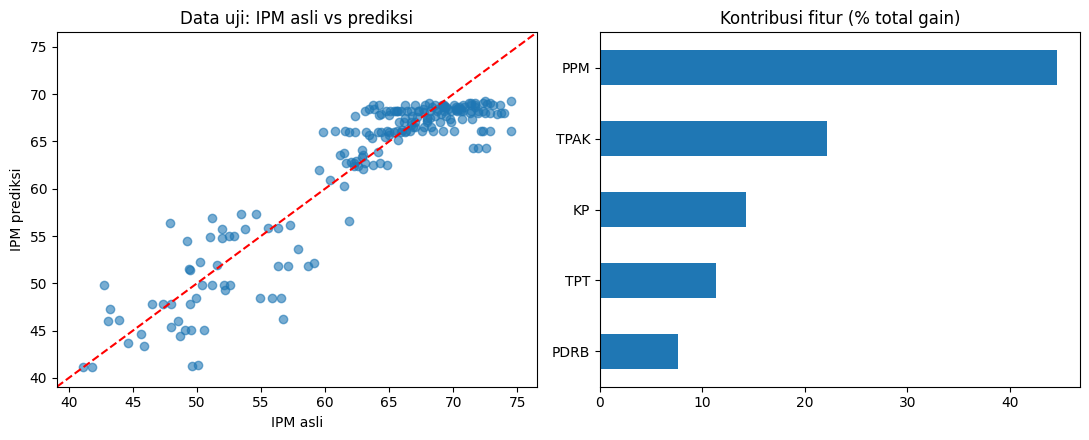

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.scatter(y_uji, pred_uji, alpha=0.6)
lim = [min(y_uji.min(), pred_uji.min()) - 2, max(y_uji.max(), pred_uji.max()) + 2]
ax1.plot(lim, lim, "r--"); ax1.set_xlim(lim); ax1.set_ylim(lim)
ax1.set_xlabel("IPM asli"); ax1.set_ylabel("IPM prediksi"); ax1.set_title("Data uji: IPM asli vs prediksi")

kontribusi.plot.barh(ax=ax2, title="Kontribusi fitur (% total gain)")

plt.tight_layout()
plt.show()